# 04 - Training-only U.S. feature analysis

Use the **approved global split restricted to U.S. candidates**. Describe campaign associations using only training outcomes; this keeps future U.S. test cases out of exploratory model choices.

The default U.S. baseline uses **conservative launch-time features**, excluding unverified `funded date` timing, title/slug flags and reward tiers. These feature families may be considered later only if their historical availability is verified. All learned category medians are refit inside CV by the modeling pipeline.

In [1]:
from pathlib import Path
import sys
HERE = Path.cwd()
PROJECT_ROOT = next((p for p in [HERE, *HERE.parents] if (p / "utils" / "preprocessing.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open Jupyter from the repository root or notebooks directory")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
GLOBAL_DIR = PROJECT_ROOT / "data" / "Processed-Data"
US_DIR = GLOBAL_DIR / "us_only"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.preprocessing import FeatureBuilder, drop_leaks
from utils.features import rate_table, rate_plot
for path in [US_DIR / "DSI_kickstarterscrape_dataset_cleaned.csv", US_DIR / "train_project_ids.csv"]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run U.S. notebooks 02 and 03")
clean = pd.read_csv(US_DIR / "DSI_kickstarterscrape_dataset_cleaned.csv")
train_ids = pd.read_csv(US_DIR / "train_project_ids.csv")
training = clean.set_index("project id", drop=False).loc[train_ids["project id"]].copy().reset_index(drop=True)
training["target"] = train_ids["target"].astype(int).to_numpy()
assert training["status"].eq("successful").astype(int).equals(training["target"])
X_train = drop_leaks(training.drop(columns=["status", "target"]))
y_train = training["target"]
print("U.S. candidate training campaigns:", len(training))

U.S. candidate training campaigns: 26945


In [2]:
# This is descriptive only. In 05, all learned medians/encoders are fitted inside CV.
builder = FeatureBuilder(include_timing=False, include_flags=False,
                         include_reward=False, exclude_renamed=True)
engineered = builder.fit_transform(X_train)
print("Conservative engineered columns:", engineered.columns.tolist())
assert "renamed" not in engineered
assert "backers_needed" not in engineered
assert "launch_month_sin" not in engineered
display(engineered.describe(include="all").T)

Conservative engineered columns: ['log_goal', 'goal_vs_subcat', 'goal_vs_cat', 'goal_per_day', 'duration', 'category', 'subcategory', 'state']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
log_goal,26945.0,NaN,NaN,NaN,8.223598,1.29662,0.00995,7.313887,8.28223,9.047939,15.068274
goal_vs_subcat,26945.0,NaN,NaN,NaN,-0.030187,1.224878,-8.581857,-0.798202,0.0,0.693022,7.061573
goal_vs_cat,26945.0,NaN,NaN,NaN,-0.030124,1.25932,-8.111928,-0.820726,0.0,0.693047,6.550881
goal_per_day,26945.0,NaN,NaN,NaN,4.605595,1.258151,-3.505407,3.809741,4.574273,5.390566,11.478525
duration,26945.0,NaN,NaN,NaN,39.738167,17.482114,1.0,30.0,31.79,47.09,91.96
category,26945,13,Film & Video,7991,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategory,26945,49,Short Film,2467,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,26945,51,CA,5772,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
overview = pd.DataFrame({
    "rows": [len(training)],
    "successful": [int(y_train.sum())],
    "failed": [int((1 - y_train).sum())],
    "success_rate": [y_train.mean()],
})
display(overview)
display(rate_table(training, "category", min_n=40).sort_values("n", ascending=False).head(15))

,rows,successful,failed,success_rate
0,26945,14716,12229,0.54615


,n,successes,rate,ci_lo,ci_hi,vs_base
category,,,,,,
Film & Video,7991,4078,0.510324,0.499361,0.521277,-0.035825
Music,6641,4495,0.676856,0.665508,0.687999,0.130706
Publishing,2613,1015,0.388442,0.369931,0.407281,-0.157707
Art,2328,1314,0.564433,0.544201,0.584452,0.018283
Theater,1531,1072,0.700196,0.676767,0.722622,0.154046
Design,999,454,0.454454,0.423811,0.485447,-0.091695
Games,975,420,0.430769,0.400018,0.462064,-0.115380
Food,875,441,0.504000,0.470926,0.537039,-0.042150
Photography,784,340,0.433673,0.399389,0.468604,-0.112476


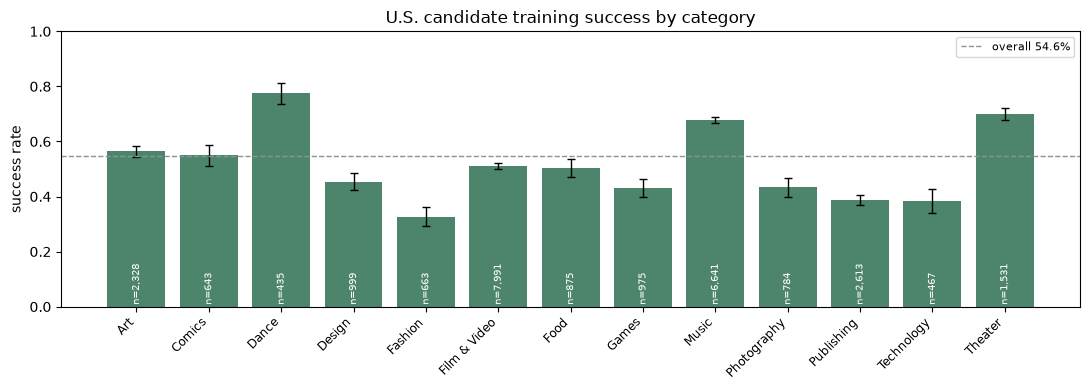

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
rate_plot(ax, rate_table(training, "category", min_n=100),
          "U.S. candidate training success by category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [5]:
goal_bins = pd.cut(training["goal"], bins=[0, 1000, 3000, 10000, 25000, 50000, np.inf],
                   labels=["<1k", "1k-3k", "3k-10k", "10k-25k", "25k-50k", ">50k"])
display(rate_table(training, goal_bins, min_n=40))
print("Numeric missingness in candidate conservative features:")
display(engineered.select_dtypes(include="number").isna().sum().sort_values(ascending=False))

,n,successes,rate,ci_lo,ci_hi,vs_base
goal,,,,,,
<1k,4822,3318,0.688096,0.674875,0.701018,0.141947
1k-3k,7458,4788,0.641995,0.631044,0.652800,0.095846
3k-10k,9881,5120,0.518166,0.508309,0.528010,-0.027983
10k-25k,3281,1203,0.366657,0.350332,0.383293,-0.179493
25k-50k,939,218,0.232162,0.206281,0.260226,-0.313988
>50k,564,69,0.122340,0.097823,0.151968,-0.423809


Numeric missingness in candidate conservative features:


log_goal          0
goal_vs_subcat    0
goal_vs_cat       0
goal_per_day      0
duration          0
dtype: int64

## Decision gate before `06`

- Confirm geographic scope (`City, ST` is **not** validated country).
- Obtain original source definitions of `funded date` and historical availability of titles and reward tiers before enabling them.
- The conservative modeling settings are `include_timing=False`, `include_flags=False`, `include_reward=False`, `exclude_renamed=True`.
- Analyze relationships as **associations**, not evidence that changing a goal or category causally improves outcomes.